# 🛒 Market Basket Analysis – Retail Business Insights
*Retail Analytics | Product Associations | Business Recommendations*

*Python · Pandas · Matplotlib · Association Rules*

**From Transaction Data to Retail Decisions**

**Introduction**

Imagine a supermarket provides us with its sales data. As data scientists, our goal is not just to create charts, but to identify the best-selling products, discover which items customers buy together, and determine how these insights can support better business decisions.

This project combines **Exploratory Data Analysis (EDA)** and **Association Rule Mining** to uncover purchasing patterns. We will use clear, concise Python code to turn transaction data into **actionable business insights**.

**Dataset source:** [Aman Kharwal – Market Basket Analysis using Python (2023)](https://amanxai.com/2023/10/16/market-basket-analysis-using-python/)

**Business Problem | What Does the Retailer Want to Know?**

- **Which products sell the most?** → Identify best-selling products and support inventory planning.
- **How large are shopping baskets?** → Understand typical purchasing patterns.
- **Which products are bought together?** → Identify product pairs in shopping baskets.
- **Which product combinations are promising?** → Evaluate associations using Support, Confidence and Lift.
- **What business actions should the retailer test?** → Suggest cross-selling, product placement and promotional experiments.
- **How might recommendations differ between Germany and the US?** → Explore market-specific test ideas using external research, not country data from this CSV.

**Problem Type:** *Descriptive Retail Analytics / Unsupervised Association Rule Mining*

**Methodology:** There is no target variable or supervised prediction. A traditional train/test split and metrics such as accuracy or training loss are not needed for this descriptive analysis. Instead, we evaluate association rules using **Support, Confidence and Lift**.

**Dataset Overview & Data Dictionary**

Each row represents a **product line item** in a transaction. Rows with the same `BillNo` belong to the same shopping basket.

| Column | Description |
|---|---|
| `BillNo` | Invoice or shopping basket identifier |
| `Itemname` | Product name |
| `Quantity` | Number of units recorded in the line item |
| `Price` | Listed price (unit or line total not confirmed) |
| `CustomerID` | Customer identifier (inconsistent within some invoices) |

**Data Limitations:**

- **No transaction dates:** We cannot analyze seasonality or sales trends over time
- **Inconsistent CustomerIDs:** Some invoices contain more than one customer ID. Customer-level loyalty or spending analysis would be unreliable
- **Unclear price definition:** We cannot calculate verified revenue or profit from `Price`
- **No country information:** This CSV cannot be used to compare German and US shoppers directly

**Import Libraries**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter
from pathlib import Path

**Load the Dataset**

Keep `market_basket_dataset.csv` next to this notebook. On Kaggle, use **Add Input** to attach the file; the code also searches the Kaggle input folder

In [2]:
csv_path = Path("market_basket_dataset.csv")
if not csv_path.exists() and Path("/kaggle/input").exists():
    csv_path = next(Path("/kaggle/input").rglob("market_basket_dataset.csv"), csv_path)
df = pd.read_csv(csv_path)
df.head()

,BillNo,Itemname,Quantity,Price,CustomerID
0,1000,Apples,5,8.30,52299
1,1000,Butter,4,6.06,11752
2,1000,Eggs,4,2.66,16415
3,1000,Potatoes,4,8.10,22889
4,1004,Oranges,2,7.26,52255


**Data Check | Is the Data Usable?**

Before analyzing the data, let's check the number of rows, missing values and duplicate records

In [3]:
print("Rows, columns:", df.shape)
print("Baskets:", df.BillNo.nunique(), "| Products:", df.Itemname.nunique())
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Rows, columns: (500, 5)
Baskets: 153 | Products: 19
Missing values:
 BillNo        0
Itemname      0
Quantity      0
Price         0
CustomerID    0
dtype: int64
Duplicate rows: 0


In [4]:
problem_bills = (df.groupby("BillNo").CustomerID.nunique() > 1).sum()
print("Invoices with multiple CustomerIDs:", problem_bills)

Invoices with multiple CustomerIDs: 112


**Data Preparation**

We will use only valid product names and positive quantities. Products are grouped by invoice number (`BillNo`). A `set` ensures that each product is counted only once per basket, even if it appears multiple times

In [5]:
df = df.dropna(subset=["BillNo", "Itemname"]).drop_duplicates()
df = df[df["Quantity"] > 0].copy()
baskets = df.groupby("BillNo")["Itemname"].apply(set)
print("Valid baskets:", len(baskets))

Valid baskets: 153


**Question: Which Products Sell the Most?**

Let's compare total `Quantity` for each product. This chart shows **units sold**, not revenue or profit

,Units sold
Itemname,
Bananas,119
Cheese,99
Coffee,88
Cereal,87
Milk,86
Oranges,81
Sugar,79
Tomatoes,79
Potatoes,78


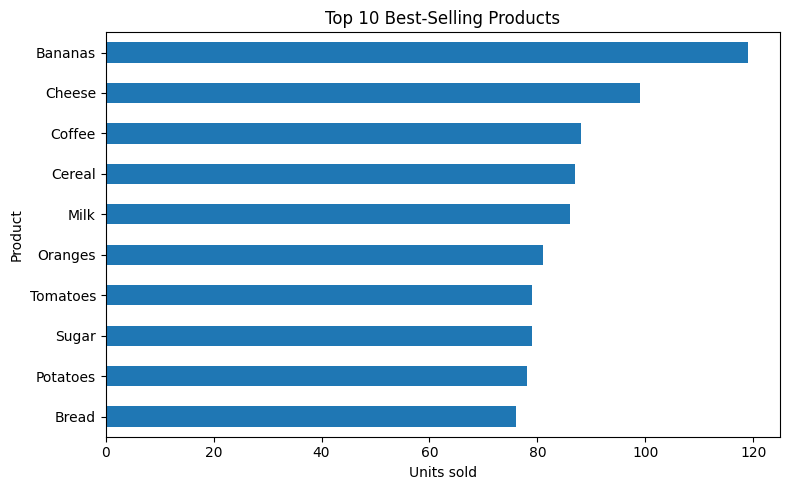

In [6]:
top_products = df.groupby("Itemname")["Quantity"].sum().nlargest(10)
display(top_products.to_frame("Units sold"))

top_products.sort_values().plot.barh(figsize=(8, 5), title="Top 10 Best-Selling Products")
plt.xlabel("Units sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

**Question: How Large Are Shopping Baskets?**

We examine the number of **unique products** in each basket. This shows how many different products appear in typical shopping baskets, not their monetary value or total units

Average different products per basket: 3.27
Median: 2.0


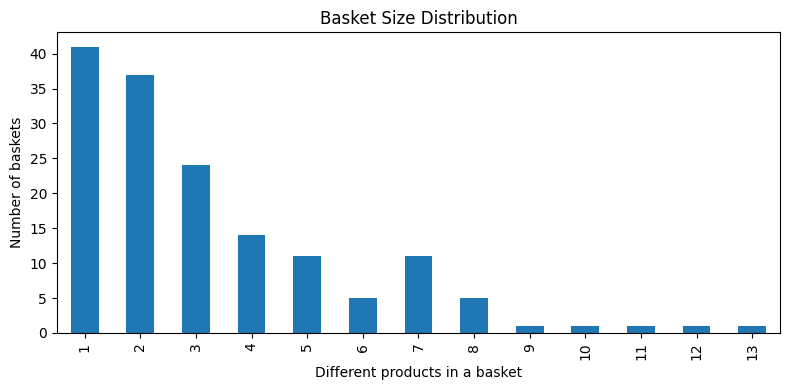

In [7]:
basket_sizes = baskets.apply(len)
print("Average different products per basket:", round(basket_sizes.mean(), 2))
print("Median:", basket_sizes.median())

basket_sizes.value_counts().sort_index().plot.bar(figsize=(8, 4), title="Basket Size Distribution")
plt.xlabel("Different products in a basket")
plt.ylabel("Number of baskets")
plt.tight_layout()
plt.show()

**Question: Which Products Are Bought Together?**

First, let's count product pairs. `combinations` finds pairs within each basket, and `Counter` counts how many baskets contain each pair. **No extra package such as `mlxtend` is needed**

,Baskets
Cereal + Cheese,12
Milk + Oranges,12
Bread + Coffee,11
Cereal + Onions,10
Bananas + Potatoes,10
Oranges + Potatoes,10
Butter + Potatoes,9
Potatoes + Tomatoes,9
Bread + Oranges,9
Bread + Potatoes,9


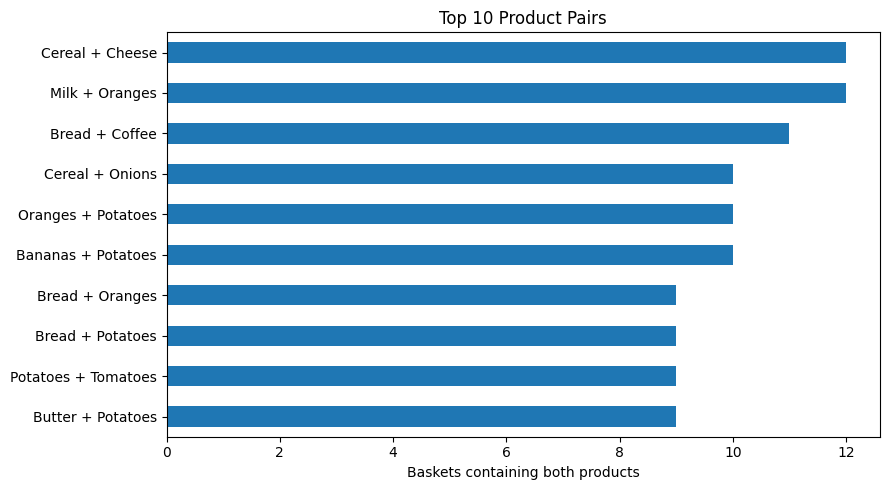

In [8]:
pair_counts = Counter(pair for items in baskets for pair in combinations(sorted(items), 2))
top_pairs = pd.Series({f"{a} + {b}": n for (a, b), n in pair_counts.most_common(10)}, name="Baskets")
display(top_pairs.to_frame())

top_pairs.sort_values().plot.barh(figsize=(9, 5), title="Top 10 Product Pairs")
plt.xlabel("Baskets containing both products")
plt.tight_layout()
plt.show()

**Question: Which Product Combinations Are Promising?**

The pairs appearing most often do not necessarily have the **strongest association**. We also need to consider how popular each product is.

- **Support:** The proportion of all baskets containing both products
- **Confidence (A → B):** The proportion of baskets containing A that also contain B. **Direction matters**
- **Lift:** The association relative to independent purchasing. `Lift > 1` indicates a positive association, but does **not** prove that one purchase causes the other

Below, we calculate **two-product association rules** directly, without requiring the more advanced Apriori itemset search. We use exploratory thresholds of **at least 8 baskets**, **30% confidence** and **Lift > 1** to shortlist candidates. These are practical screening choices, not statistical proof

In [9]:
item_counts = Counter(item for items in baskets for item in items)
N = len(baskets)
rules = []
for (a, b), count in pair_counts.items():
    for left, right in [(a, b), (b, a)]:
        support = count / N
        confidence = count / item_counts[left]
        lift = confidence / (item_counts[right] / N)
        rules.append([left, right, count, support, confidence, lift])

rules = pd.DataFrame(rules, columns=["If", "Then", "Baskets", "Support", "Confidence", "Lift"])
strong_rules = rules.query("Baskets >= 8 and Confidence >= 0.30 and Lift > 1").sort_values(
    ["Lift", "Baskets"], ascending=False)
display(strong_rules.head(12).round(2))

,If,Then,Baskets,Support,Confidence,Lift
100,Chicken,Pasta,8,0.05,0.40,2.66
101,Pasta,Chicken,8,0.05,0.35,2.66
272,Milk,Oranges,12,0.08,0.50,2.64
273,Oranges,Milk,12,0.08,0.41,2.64
198,Juice,Tea,8,0.05,0.35,2.31
199,Tea,Juice,8,0.05,0.35,2.31
150,Chicken,Potatoes,8,0.05,0.40,2.27
38,Bread,Coffee,11,0.07,0.48,2.22
39,Coffee,Bread,11,0.07,0.33,2.22
46,Bread,Potatoes,9,0.06,0.39,2.22


**Visualization | Promising Product Combinations**

The bars show **Lift** for distinct product pairs. A high Lift is not a guarantee of increased sales. With a small dataset, these associations should be tested in controlled retail experiments

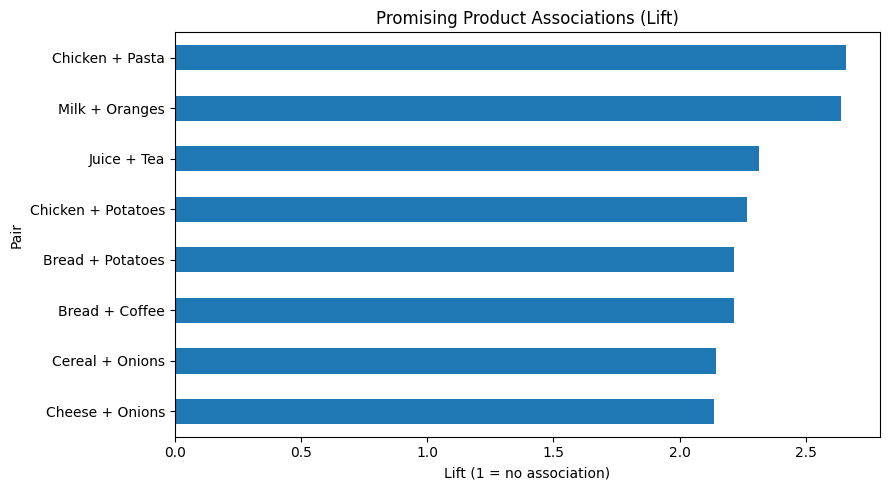

In [10]:
plot_rules = strong_rules.copy()
plot_rules["Pair"] = [" + ".join(sorted((a, b))) for a, b in zip(plot_rules["If"], plot_rules["Then"])]
plot_rules = plot_rules.drop_duplicates("Pair").head(8)
plot_rules.set_index("Pair")["Lift"].sort_values().plot.barh(
    figsize=(9, 5), title="Promising Product Associations (Lift)")
plt.xlabel("Lift (1 = no association)")
plt.tight_layout()
plt.show()

**Example | How Do We Interpret a Rule?**

**Milk → Oranges**

- **12 out of 24** baskets containing `Milk` also contain `Oranges`
- **Support:** 12 / 153 = **7.8%** of all baskets contain both products
- **Confidence:** 12 / 24 = **50%** of Milk baskets also contain Oranges
- **Lift:** 0.50 / (29 / 153) = **2.64** — approximately 2.64 times the co-occurrence expected under independence

**Interpretation:** Milk and Oranges are a promising pair for a pilot test. This association does **not** prove that a campaign would increase sales

**Business Recommendations | What Should the Retailer Test?**

| Observation | Suggested action | How to validate |
|---|---|---|
| Bananas have the highest unit sales (119 units) | Prioritize checking banana stock availability | Compare with real-time stock and time-based sales data |
| Milk + Oranges appear together in 12 baskets | Test a cross-selling suggestion | Run a controlled promotion; measure incremental sales and margin |
| Cereal + Cheese appear together in 12 baskets | Test a basket recommendation | Compare promoted and control groups |
| Bread + Coffee appear together in 11 baskets | Test product placement or a shopping-list suggestion | Monitor basket size, incremental sales and profitability |

**Important:** These are **hypotheses, not verified commercial outcomes**. Without dates, reliable customer IDs, product costs and a verified price definition, we cannot measure seasonality, customer loyalty, revenue uplift or profit.

**Retail Market Perspectives | Germany and the US**

This dataset **does not identify the country of any transaction**. The following ideas come from **external retail research** and are not findings from our basket data

| Market | External research context | Suggested experiment |
|---|---|---|
| **Germany** | Value for money, store accessibility and price comparisons are important grocery-shopping factors. | Test **value-focused bundles**, clear shelf labels or app coupons. |
| **United States** | Grocery shoppers place importance on an easy in-store experience and on using digital tools while shopping. | Test **app-based product suggestions** or convenience-focused product placement. |

**Sources:** [KPMG / EHI Consumer Barometer 2026 (Germany)](https://kpmg.com/de/en/media/press-releases/2026/06/between-lifestyle-and-price-sensitivity%20.html) · [FMI U.S. Grocery Shopper Trends 2026](https://www.fmi.org/our-research/research-reports/u-s-grocery-shopper-trends)

**Caution:** These studies examine different populations and questions. This is a comparison of **possible test approaches**, not proof that customers in one country prefer certain product pairs

**Conclusion**

In this project, we analyzed **500 product line items from 153 shopping baskets**. We explored best-selling products, basket sizes and commonly purchased product pairs. We then evaluated associations using **Support, Confidence and Lift**.

**Key insights:** Bananas led in unit volume (119 units). The Milk → Oranges rule has **7.8% support**, **50% confidence** and **2.64 Lift**, making it an interesting candidate for a controlled cross-selling test.

**Data Science perspective:** Our output is **testable retail hypotheses**, not guaranteed sales growth. A real retailer would validate these ideas with transaction dates, reliable customer identifiers, stock data, product costs and campaign results. Germany- and US-specific suggestions require separate market evidence and testing.